# SHAP analysis
Global and per-order explanations with SHAP (TreeExplainer), cross-checked against the production reason codes from `RiskScorer`, which use a cheaper what-if method so the API needs no SHAP dependency.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "3_Model").exists():
    ROOT = ROOT.parent
for p in ("3_Model", "3_Model/training", "4_Backend/utils"):
    sys.path.insert(0, str(ROOT / p))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"


In [2]:
import shap
from risk_scoring import RiskScorer
scorer = RiskScorer()
test = pd.read_csv(ROOT / '3_Model/saved_models/test_set.csv')
X = test[scorer.features].sample(1500, random_state=0)
explainer = shap.TreeExplainer(scorer.model)
sv = explainer.shap_values(X)
sv.shape

C:\Users\loida\AI-Fraud-Detector\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(1500, 21)

## Global: which signals drive risk overall

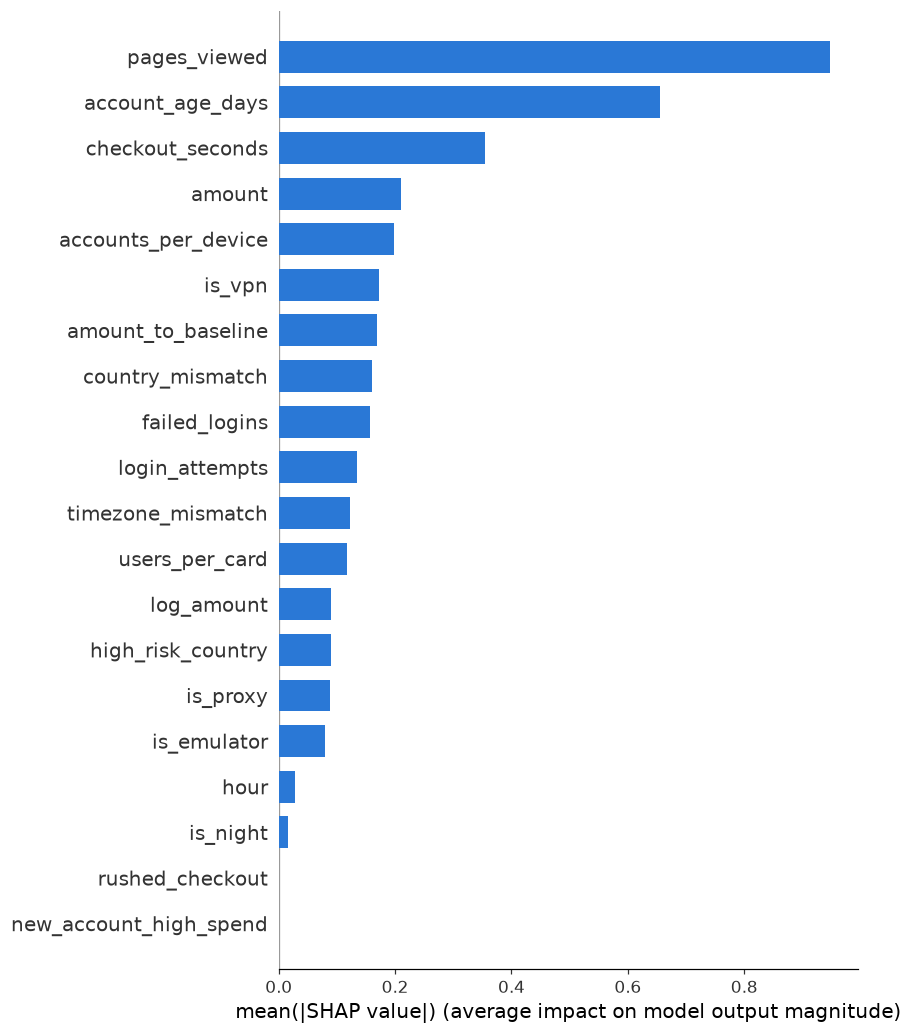

In [3]:
shap.summary_plot(sv, X, plot_type='bar', show=False, color=BLUE)
plt.tight_layout()

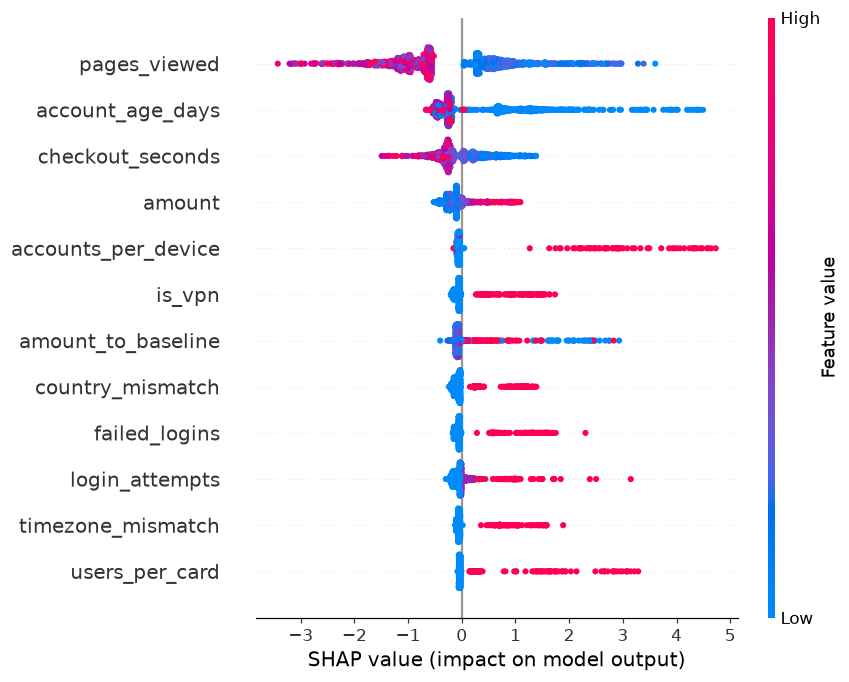

In [4]:
shap.summary_plot(sv, X, show=False, max_display=12)
plt.tight_layout()

## Local: one blocked order
SHAP top contributors vs the reasons shown to the merchant.

In [5]:
flagged = test[scorer._scores(test) >= 70].iloc[0:1]
local = pd.Series(explainer.shap_values(flagged[scorer.features])[0], index=scorer.features)
print('SHAP top-5 (log-odds):'); print(local.sort_values(ascending=False).head(5).round(2))
print('\nRiskScorer reasons:'); [print(' -', r['text'], f"({r['impact']}%)") for r in scorer.score(flagged)[0]['reasons']]

SHAP top-5 (log-odds):
users_per_card       2.65
pages_viewed         2.35
high_risk_country    1.99
country_mismatch     1.39
account_age_days     1.39
dtype: float64

RiskScorer reasons:
 - Card used by 9 different accounts (30%)
 - IP location (NG) differs from billing country (US) (27%)
 - Brand-new account (7.8 days old) (23%)
 - High-risk country involved (20%)


[None, None, None, None]

## Agreement between SHAP and production reasons
Share of flagged orders where the merchant-facing top reason is among SHAP's top-3 feature groups.

In [6]:
from risk_scoring import REASON_GROUPS
feat2group = {f: g for g, fs in REASON_GROUPS.items() for f in fs}
fl = test[scorer._scores(test) >= 30].head(200)
res = scorer.score(fl)
sv_fl = explainer.shap_values(fl[scorer.features])
agree = []
for r, row in zip(res, sv_fl):
    if not r['reasons']: continue
    g = pd.Series(row, index=scorer.features).groupby(lambda f: feat2group.get(f, f)).sum()
    agree.append(r['reasons'][0]['feature'] in g.nlargest(3).index)
print(f'top reason in SHAP top-3 for {np.mean(agree):.0%} of {len(agree)} flagged orders')

top reason in SHAP top-3 for 68% of 200 flagged orders
